# 06 — Sensitivity of the recommendation

Each scenario reruns the chain from the point where the parameter enters (`notebooks/sensibilidade.py`;
run with the environment variable `SENS`) and writes to `resultados/sensibilidade/<scenario>/`:

| Scenario | What changes | Reruns |
|---|---|---|
| CT1350 / CT1550 | thermal time from sowing to maturity: 1450 ± 100 °C day | 02 → 03 → 05 |
| janela_cedo | weights 0.4 / 0.3 / 0.2 / 0.1 on the dates 15/01, 05/02, 25/02, 15/03 (sowing concentrated right after soybean) | 03 → 05 |
| janela_7datas | the 7 dates of the ZARC window (15/01 to 15/03), equal weights | 03 → 05 |

The economic scenarios (total cost, 70% coverage, ZARC Group II, 10 or 30 days to sale) do not touch the
model and are computed in notebook 05 itself (`sensibilidade_decisao.csv`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"font.size": 16})

from sensibilidade import CENARIOS, RESULTADOS

RAIZ = Path.cwd().parent
FIGURAS = RAIZ / "figuras"
ORDEM_DATAS = [f"{d:02d}/{m:02d}" for m in (1, 2, 3) for d in (5, 15, 25)]
FINAL = "L_ensemble_E_SVR"
PASTAS = {"base": RESULTADOS} | {c: RESULTADOS / "sensibilidade" / c for c in CENARIOS}
faltam = [c for c, p in PASTAS.items() if not (p / "melhor_data_semeadura_pr.csv").exists()]
print("Scenarios without results:", faltam or "none")

Scenarios without results: none


## 1. Model, cycle and decision per scenario

In [2]:
base_dec = pd.read_csv(RESULTADOS / "melhor_data_semeadura_pr.csv", index_col=0)
linhas, curvas = [], {}
for nome, pasta in PASTAS.items():
    val = pd.read_csv(pasta / "validacao_loyo_modelos.csv", index_col=0) if (pasta / "validacao_loyo_modelos.csv").exists() \
        else pd.read_csv(RESULTADOS / "validacao_loyo_modelos.csv", index_col=0)
    dec = pd.read_csv(pasta / "melhor_data_semeadura_pr.csv", index_col=0)
    risco = pd.read_csv(pasta / "risco_economico_municipio_data.csv")
    sim_arq = pasta / "simulacao_mza_pr.parquet" if (pasta / "simulacao_mza_pr.parquet").exists() else RESULTADOS / "simulacao_mza_pr.parquet"
    ciclo = pd.read_parquet(sim_arq, columns=["semeadura", "ciclo_dias"]).groupby("semeadura")["ciclo_dias"].mean()
    melhor = risco.merge(dec["melhor_data_zarc"].rename("semeadura").reset_index(), on=["cod_ibge", "semeadura"])
    curvas[nome] = risco.groupby("semeadura")["CE_rr2"].mean().loc[ORDEM_DATAS]
    ok = dec["melhor_data_zarc"].notna() & base_dec["melhor_data_zarc"].reindex(dec.index).notna()
    linhas.append({
        "cenario": nome,
        "R2_municipal": val.loc[FINAL, "R2"], "R2_anual": val.loc[FINAL, "R2_anual_estadual"],
        "RMSE_kg_ha": val.loc[FINAL, "RMSE_kg_ha"],
        "ciclo_05jan_d": ciclo["05/01"], "ciclo_15mar_d": ciclo["15/03"],
        "mesma_data_base_%": 100 * (dec.loc[ok, "melhor_data_zarc"] == base_dec.loc[dec.index[ok], "melhor_data_zarc"]).mean(),
        "melhor_05jan_n": int((dec["melhor_data_zarc"] == "05/01").sum()),
        "melhor_15mar_n": int((dec["melhor_data_zarc"] == "15/03").sum()),
        "CE_melhor_data": melhor["CE_rr2"].mean(), "p_prejuizo_melhor_data": melhor["p_prejuizo"].mean(),
        "valor_seguro_medio": risco["valor_seguro"].mean(),
    })
tab = pd.DataFrame(linhas).set_index("cenario")
tab.to_csv(RESULTADOS / "sensibilidade_cenarios.csv")
tab.round(3)

,R2_municipal,R2_anual,RMSE_kg_ha,ciclo_05jan_d,ciclo_15mar_d,mesma_data_base_%,melhor_05jan_n,melhor_15mar_n,CE_melhor_data,p_prejuizo_melhor_data,valor_seguro_medio
cenario,,,,,,,,,,,
base,0.427,0.674,1061.570,105.198,153.459,100.000,311,27,865.541,0.260,57.504
CT1350,0.393,0.611,1092.331,95.907,142.290,77.957,284,12,803.876,0.275,65.436
CT1550,0.450,0.727,1040.426,115.255,164.173,83.333,310,23,870.839,0.257,76.771
janela_cedo,0.384,0.593,1100.940,105.198,153.459,90.591,310,24,888.871,0.258,82.682
janela_7datas,0.430,0.669,1058.512,105.198,153.459,90.323,323,26,816.960,0.271,57.646


## 2. Economic scenarios (notebook 05)

In [3]:
pd.read_csv(RESULTADOS / "sensibilidade_decisao.csv").round(2)

,cenario,margem_media,p_prejuizo,mesma_melhor_data_%,municipios_com_data_apta
0,total cost,352.17,0.53,97.85,372
1,70% coverage,1345.27,0.32,99.46,372
2,ZARC Group II,1307.97,0.34,95.21,355
3,10 days to sale,1324.85,0.33,90.32,372
4,30 days to sale,1307.18,0.34,90.32,372


## 3. Certainty equivalent by sowing date

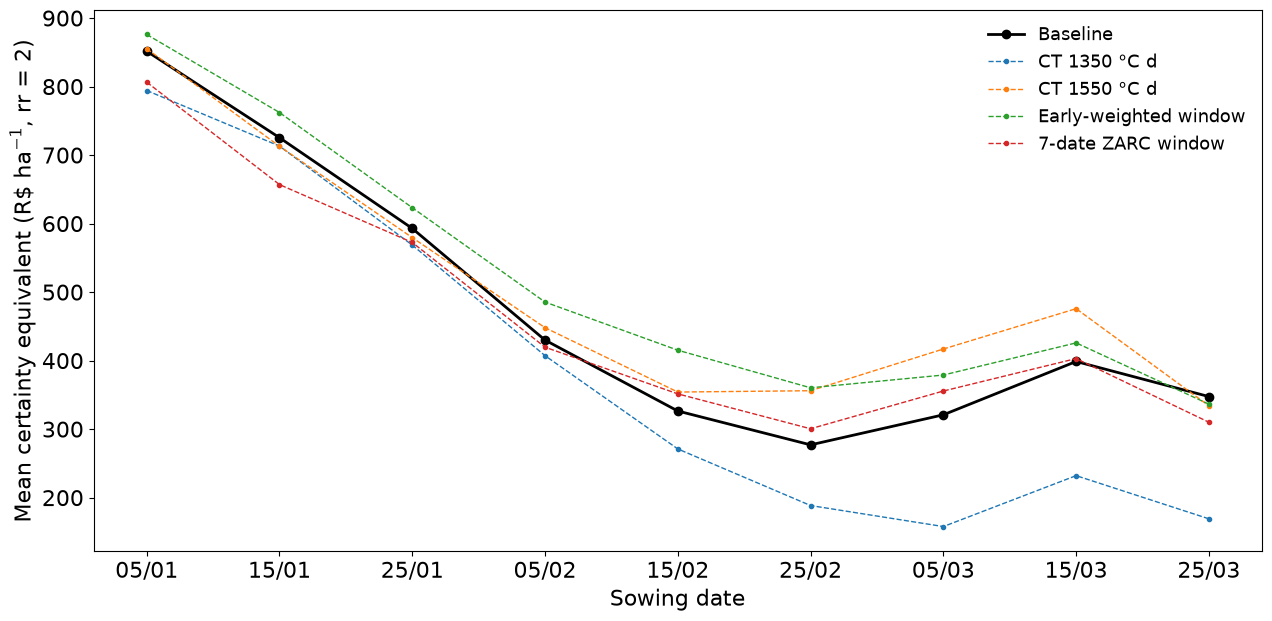

In [4]:
NOME_EN = {"base": "Baseline", "CT1350": "CT 1350 °C d", "CT1550": "CT 1550 °C d",
           "janela_cedo": "Early-weighted window", "janela_7datas": "7-date ZARC window"}
fig, ax = plt.subplots(figsize=(13, 6.5))
for nome, c in curvas.items():
    ax.plot(range(len(ORDEM_DATAS)), c.values, "k-o" if nome == "base" else "--.", lw=2 if nome == "base" else 1, label=NOME_EN[nome])
ax.set_xticks(range(len(ORDEM_DATAS)), ORDEM_DATAS)
ax.set(xlabel="Sowing date", ylabel=r"Mean certainty equivalent (R\$ ha$^{-1}$, rr = 2)")
ax.legend(frameon=False, fontsize=13)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_sensibilidade_ce.png", dpi=300)